# Digital modulation

Bits to symbols to samples and back: Gray-coded constellations, pulse
shaping, a QPSK link with its eye and spectrum, and bit error rates of five
schemes against theory, each swept with a plain `for` loop.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import erfc

import sigline as sl


def Q(x):
    return 0.5 * erfc(x / np.sqrt(2))

## 1. Constellations

`pam`, `psk` and `qam` return Gray-coded points with unit average energy:
neighbours differ in one bit, so a near miss costs one bit error.

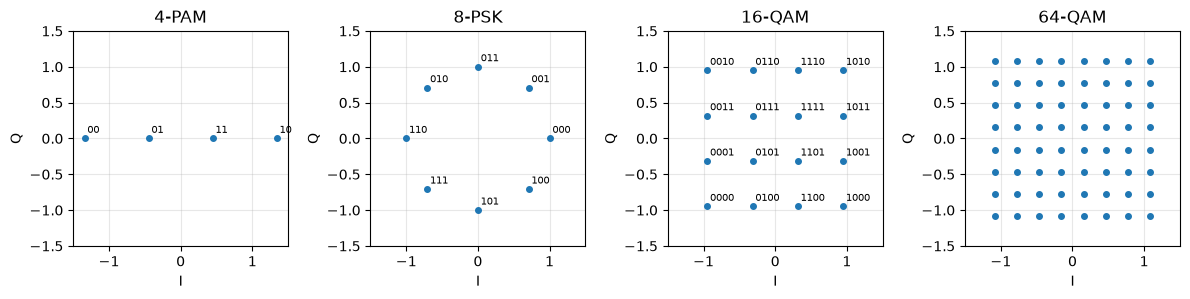

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, (name, pts) in zip(
    axes,
    {
        "4-PAM": sl.pam(4),
        "8-PSK": sl.psk(8),
        "16-QAM": sl.qam(16),
        "64-QAM": sl.qam(64),
    }.items(),
    strict=True,
):
    k = int(np.log2(len(pts)))
    ax.plot(pts.real, pts.imag, "o", ms=4)
    if len(pts) <= 16:
        for w, p in enumerate(pts):
            ax.annotate(
                format(w, f"0{k}b"),
                (p.real, p.imag),
                fontsize=7,
                xytext=(2, 4),
                textcoords="offset points",
            )
    ax.set(
        title=name,
        xlabel="I",
        ylabel="Q",
        aspect="equal",
        xlim=(-1.5, 1.5),
        ylim=(-1.5, 1.5),
    )
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 2. A shaped QPSK link

Bits, `Mapper`, root-raised-cosine `PulseShaper`, noise, `MatchedFilter`,
one sample per symbol, `Demapper`. The matched-filter output shows a wide
open eye at the symbol instants.

BERCounter1: BER 1.795e-04 (7/39000 bits), 95% CI [7.22e-05, 3.70e-04], delay 20 bits


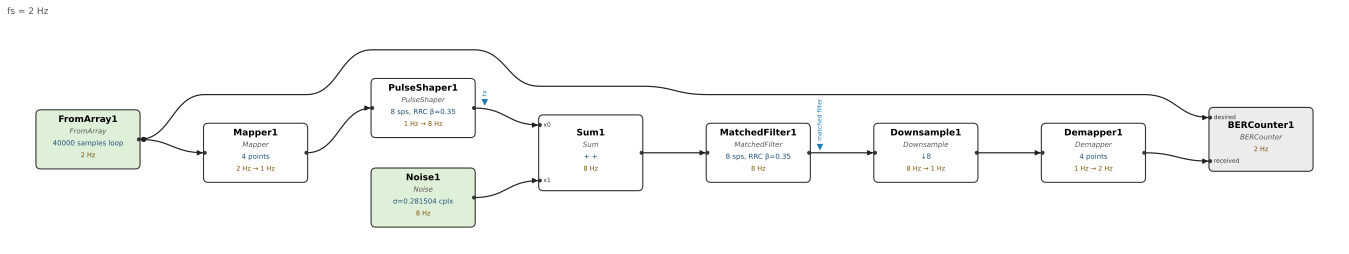

In [3]:
sps, ebn0_db = 8, 8.0
esn0 = 2 * 10 ** (ebn0_db / 10)
bits = sl.FromArray(
    np.random.default_rng(1).integers(0, 2, 40_000).astype(float), loop=True
)
tx = bits >> sl.Mapper(sl.psk(4)) >> sl.PulseShaper(sps)
rx = tx + sl.Noise(np.sqrt(1 / esn0), seed=2, complex=True, fs=1.0 * sps)
mf = rx >> sl.MatchedFilter(sps)
ber = sl.BERCounter(sync=500)
mf >> sl.Downsample(sps) >> sl.Demapper(sl.psk(4)) >> ber["received"]
bits >> ber["desired"]

d = sl.Diagram(ber, fs=2.0)
spec = d.probe(tx, sink=sl.SpectrumAnalyzer(nfft=256, label="tx"))
eye = d.probe(mf, sink=sl.EyeDiagram(sps, range=(-1.6, 1.6), label="matched filter"))
d.run(n=40_000, chunk=4000)
print(ber.summary())
d

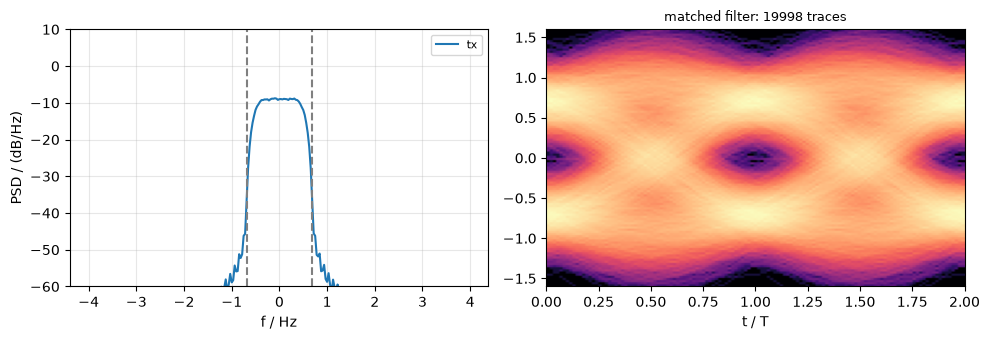

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
spec.plot(ax=a1, max_hold=False)
a1.axvline(-(1 + 0.35) / 2 * 1.0, color="gray", ls="--")
a1.axvline((1 + 0.35) / 2 * 1.0, color="gray", ls="--")
a1.set_ylim(-60, 10)
eye.plot(ax=a2)
fig.tight_layout()
plt.show()

The dashed lines mark $(1+\beta) R_s/2$, where the RRC spectrum ends.

## 3. Bit error rates against theory

A sweep is a `for` loop over $E_b/N_0$. Linear schemes run at the symbol
rate (unit-energy pulses make that equivalent). Theory, Gray coding, AWGN:

| scheme | $P_b$ |
| --- | --- |
| BPSK, QPSK | $Q(\sqrt{2 E_b/N_0})$ |
| square $M$-QAM | $\approx \frac{4}{k}(1-\frac{1}{\sqrt M})\,Q(\sqrt{3k E_b/N_0/(M-1)})$ |
| noncoherent BFSK | $\tfrac12 e^{-E_b/2N_0}$ |

In [5]:
def linear_link(points, ebn0_db, n_bits=120_000):
    k = int(np.log2(len(points)))
    esn0 = k * 10 ** (ebn0_db / 10)
    bits = sl.FromArray(np.random.default_rng(3).integers(0, 2, n_bits).astype(float))
    meter = sl.BERCounter(sync=600, lock_ber=0.45)  # BFSK reaches 0.3
    rx = (bits >> sl.Mapper(points)) + sl.Noise(
        np.sqrt(1 / esn0), seed=4, complex=True, fs=1.0
    )
    rx >> sl.Demapper(points) >> meter["received"]
    bits >> meter["desired"]
    return sl.Diagram(meter, fs=float(k)), meter


def fsk_link(ebn0_db, n_bits=120_000, sps=8):
    ebn0 = 10 ** (ebn0_db / 10)
    bits = sl.FromArray(np.random.default_rng(5).integers(0, 2, n_bits).astype(float))
    meter = sl.BERCounter(sync=600, lock_ber=0.45)
    rx = (bits >> sl.FSKMod(2, sps)) + sl.Noise(
        np.sqrt(sps / ebn0), seed=6, complex=True, fs=float(sps)
    )
    rx >> sl.FSKDemod(2, sps) >> meter["received"]
    bits >> meter["desired"]
    return sl.Diagram(meter, fs=1.0), meter


def linear_ber(points, ebn0_db, n_bits=120_000):
    d, meter = linear_link(points, ebn0_db, n_bits)
    k = int(np.log2(len(points)))
    d.run(n=n_bits // (6 * k) * 6 * k, chunk=6000)
    return meter.ber


def fsk_ber(ebn0_db, n_bits=120_000):
    d, meter = fsk_link(ebn0_db, n_bits)
    d.run(n=n_bits, chunk=8000)
    return meter.ber


One link per point of the curves; the linear ones differ only in the constellation.

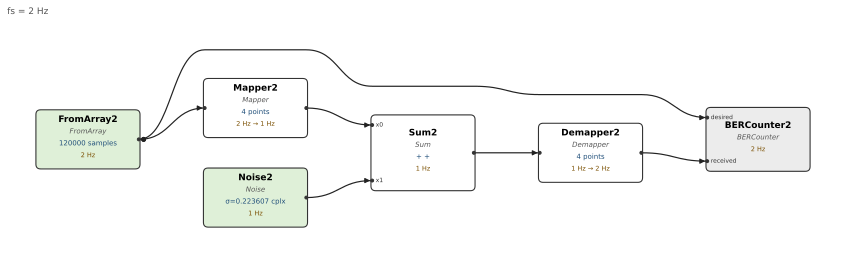

In [6]:
linear_link(sl.psk(4), 10.0)[0]

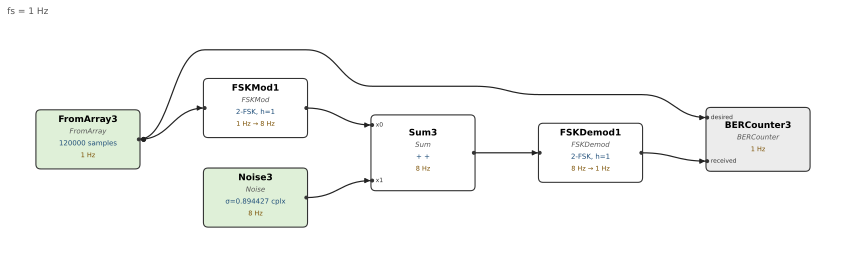

In [7]:
fsk_link(10.0)[0]

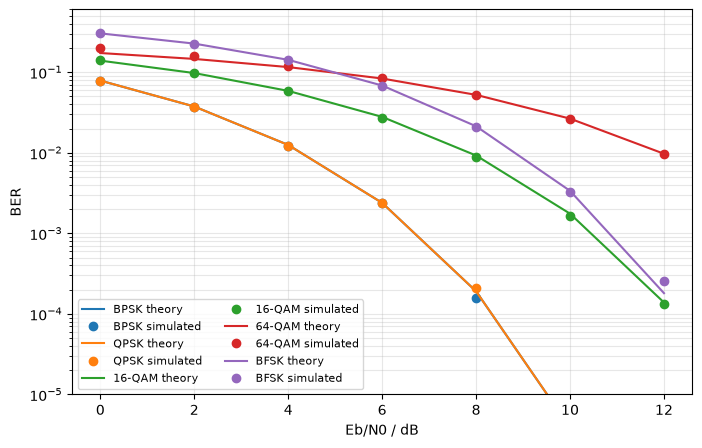

In [8]:
ebn0 = np.arange(0, 13, 2.0)
g = 10 ** (ebn0 / 10)
schemes = {
    "BPSK": (lambda e: linear_ber(sl.psk(2), e), Q(np.sqrt(2 * g))),
    "QPSK": (lambda e: linear_ber(sl.psk(4), e), Q(np.sqrt(2 * g))),
    "16-QAM": (
        lambda e: linear_ber(sl.qam(16), e),
        4 / 4 * (1 - 1 / 4) * Q(np.sqrt(3 * 4 * g / 15)),
    ),
    "64-QAM": (
        lambda e: linear_ber(sl.qam(64), e),
        4 / 6 * (1 - 1 / 8) * Q(np.sqrt(3 * 6 * g / 63)),
    ),
    "BFSK": (fsk_ber, 0.5 * np.exp(-g / 2)),
}

fig, ax = plt.subplots(figsize=(8, 5))
for name, (simulate, theory) in schemes.items():
    sim = np.array([simulate(e) for e in ebn0])
    (line,) = ax.semilogy(ebn0, theory, label=f"{name} theory")
    ax.semilogy(
        ebn0[sim > 0],
        sim[sim > 0],
        "o",
        color=line.get_color(),
        label=f"{name} simulated",
    )
ax.set(xlabel="Eb/N0 / dB", ylabel="BER", ylim=(1e-5, 0.6))
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8, ncol=2)
plt.show()

Points below about $10^{-5}$ are missing: 120 000 bits rarely show an error
there. QPSK has the same BER as BPSK at twice the bits per symbol. For
$10^{-4}$, 16- and 64-QAM need 3.8 and 8.1 dB more $E_b/N_0$ than QPSK
(theory) for two and three times its bits per symbol. The QAM formula is an
approximation that reads slightly low at small $E_b/N_0$ (64-QAM at 0 dB).

## Summary

- `pam`, `psk`, `qam`: Gray-coded constellations.
- `Mapper`, `Demapper`, `WordsToBits`, `BitsToWords`: bits and symbols.
- `PulseShaper`, `MatchedFilter` (`rrc_taps`): Nyquist pulse shaping.
- `FSKMod`, `FSKDemod`: continuous-phase FSK, noncoherent detection.
- Each matches its closed-form bit error rate.